# 3. The lasso

$$\hat\beta^{\text{lasso}} = \arg\min_\beta \; \frac{1}{2n}\lVert y - X\beta \rVert^2 + \lambda \lVert\beta\rVert_1$$

**Learning goals**: why the L1 penalty produces exact zeros, soft-thresholding, coordinate descent
from scratch, paths, and the lasso's known weaknesses.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

## Soft-thresholding
With orthonormal predictors the lasso solution has a closed form:
$$\hat\beta_j^{\text{lasso}} = S(\hat\beta_j^{\text{OLS}}, \lambda) = \text{sign}(\hat\beta_j^{\text{OLS}}) \max(|\hat\beta_j^{\text{OLS}}| - \lambda, 0)$$
Ridge instead scales: $\hat\beta_j^{\text{OLS}}/(1+\lambda)$. Small OLS coefficients become exactly
zero under the lasso, and large ones are shifted towards zero by a constant amount.

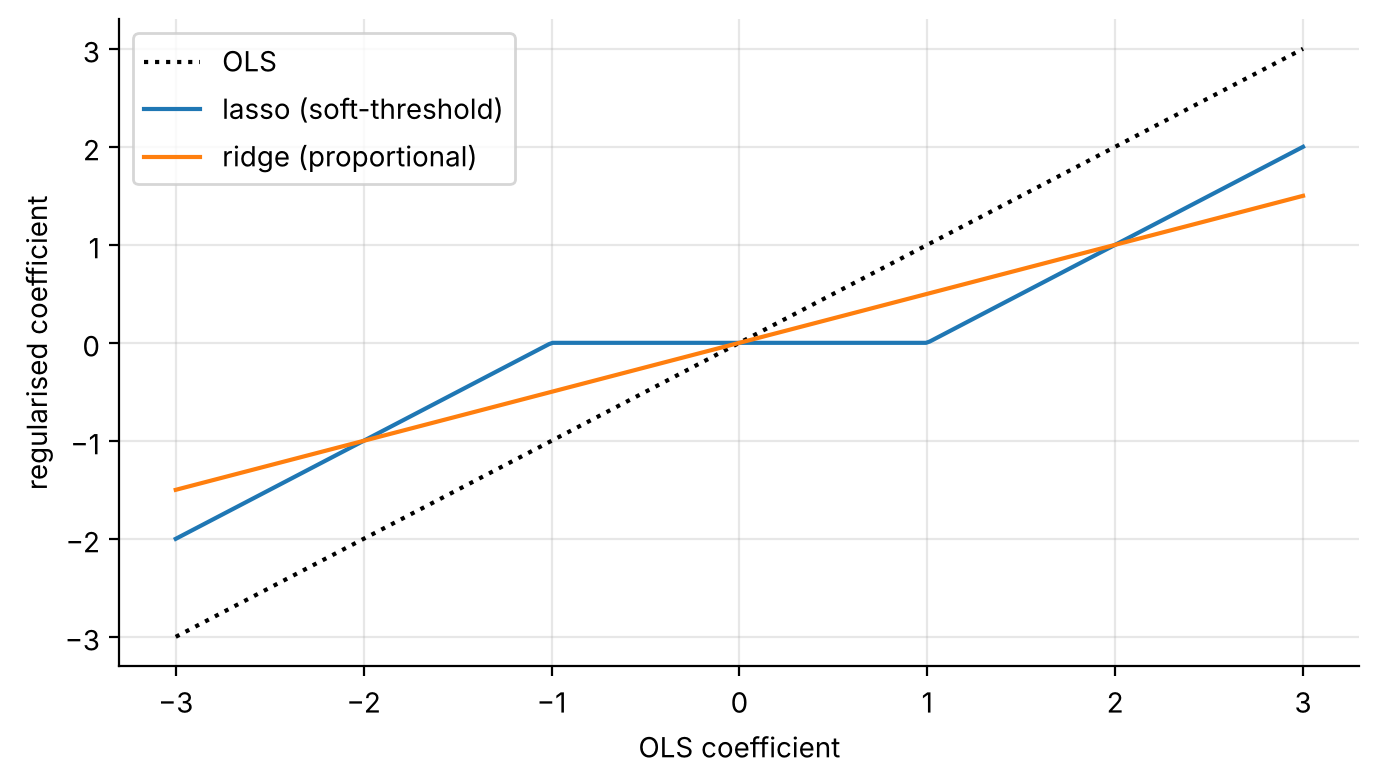

In [2]:
b = np.linspace(-3, 3, 300); lam = 1.0
plt.plot(b, b, "k:", label="OLS")
plt.plot(b, np.sign(b) * np.maximum(np.abs(b) - lam, 0), label="lasso (soft-threshold)")
plt.plot(b, b / (1 + lam), label="ridge (proportional)")
plt.xlabel("OLS coefficient"); plt.ylabel("regularised coefficient"); plt.legend();

## Why corners create zeros
Equivalently, minimise RSS subject to $\sum|\beta_j| \le t$. The L1 constraint region is a diamond
with corners on the axes; the RSS contours usually first touch it at a corner, where some
coefficients are exactly zero. The ridge constraint is a circle with no corners.

## Coordinate descent from scratch
Cycle through coefficients, each time solving the one-dimensional problem exactly with
soft-thresholding. With standardised columns ($\frac1n\sum x_{ij}^2=1$):
$$\beta_j \leftarrow S\Big(\tfrac{1}{n} x_j^\top r_{(j)}, \lambda\Big), \qquad r_{(j)} = y - \sum_{k\ne j} x_k\beta_k$$

In [3]:
def soft(z, t):
    return np.sign(z) * np.maximum(np.abs(z) - t, 0.0)

def lasso_cd(X, y, lam, n_iter=500, tol=1e-8):
    n, p = X.shape
    b = np.zeros(p); r = y.copy()
    for _ in range(n_iter):
        b_old = b.copy()
        for j in range(p):
            r += X[:, j] * b[j]                 # remove j's contribution
            b[j] = soft(X[:, j] @ r / n, lam)   # 1-D lasso solution
            r -= X[:, j] * b[j]
        if np.max(np.abs(b - b_old)) < tol:
            break
    return b

from sklearn.linear_model import Lasso
n, p = 100, 20
X = rng.normal(size=(n, p)); X = (X - X.mean(0)) / X.std(0)
beta = np.r_[[2, -1.5, 1, 0.5], np.zeros(p - 4)]
y = X @ beta + rng.normal(size=n); y = y - y.mean()
b_ours = lasso_cd(X, y, lam=0.2)
b_skl = Lasso(alpha=0.2, fit_intercept=False, tol=1e-10, max_iter=100000).fit(X, y).coef_
print("ours   :", np.round(b_ours, 3))
print("sklearn:", np.round(b_skl, 3))
print("non-zero:", (np.abs(b_ours) > 0).sum(), "of", p)

ours   : [ 1.908 -1.174  1.062  0.33   0.046  0.     0.    -0.     0.     0.
 -0.    -0.     0.    -0.    -0.    -0.     0.     0.011 -0.     0.   ]
sklearn: [ 1.908 -1.174  1.062  0.33   0.046  0.     0.    -0.     0.     0.
 -0.    -0.     0.    -0.    -0.    -0.     0.     0.011 -0.     0.   ]
non-zero: 6 of 20


## Lasso paths: variables enter one at a time

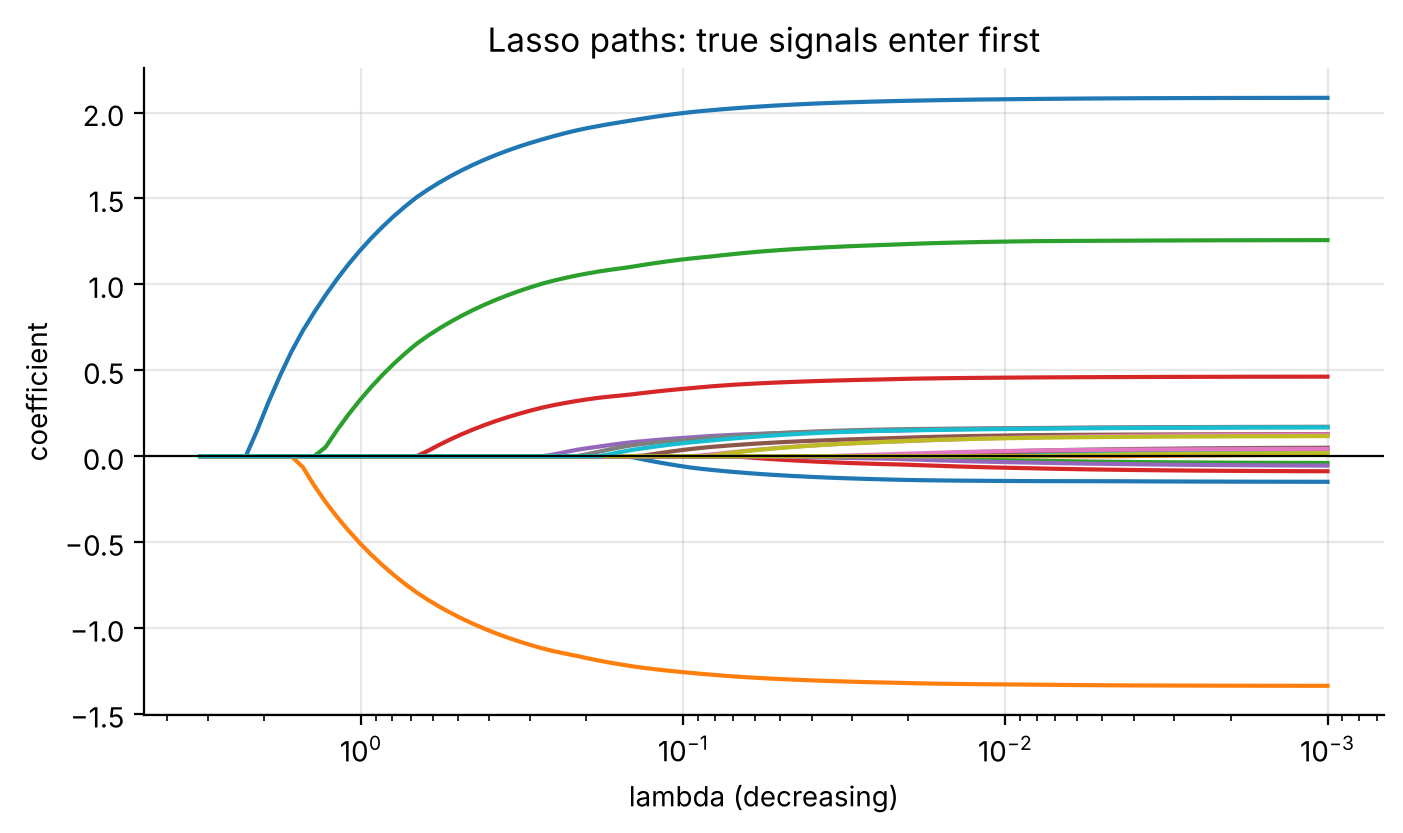

In [4]:
from sklearn.linear_model import lasso_path
alphas, coefs, _ = lasso_path(X, y, alphas=np.logspace(0.5, -3, 100))
plt.semilogx(alphas, coefs.T); plt.gca().invert_xaxis(); plt.axhline(0, c="k", lw=0.8)
plt.xlabel("lambda (decreasing)"); plt.ylabel("coefficient"); plt.title("Lasso paths: true signals enter first");

## On the GDP data: which indicators does the lasso pick?

In [5]:
# The project's real data: the horizon-2 design (nowcast made at the end of the quarter)
from nowcast.features import build_all, main_spec
from nowcast.models import Standardiser
B = build_all([2])
X = B["X"][2]
X = X[[c for c in X.columns if main_spec(c)]]       # real-time output + other indicators
y = B["first"].reindex(X.index)                      # target: ONS's first published estimate
keep = y.notna() & ~X.index.isin(pd.period_range("2020Q1", "2021Q2", freq="Q"))
X, y = X[keep], y[keep]
names = list(X.columns)
print(X.shape, "quarters x features")

(108, 236) quarters x features


In [6]:
from sklearn.linear_model import LassoCV
from nowcast.models import time_folds
st = Standardiser().fit(X.values); Z = st.transform(X.values)
m = LassoCV(cv=time_folds(len(y)), alphas=60, max_iter=50000).fit(Z, y.values)
sel = pd.Series(m.coef_, index=names)
sel = sel[sel.abs() > 1e-10].sort_values(key=np.abs, ascending=False)
print(f"lambda = {m.alpha_:.4f}: {len(sel)} of {len(names)} features selected")
sel.head(12).round(3)

lambda = 0.0360: 30 of 236 features selected


RT_IOP_l0      0.093
RT_IOS_l2      0.092
GDP_q1         0.077
AP2Y_l3        0.060
D7BT_l3       -0.059
RT_IOP_l1      0.058
IUMABEDR_l0    0.052
RT_IOM_l2      0.048
GDP_q2         0.042
XUMAUSS_l0     0.034
MGRZ_l0        0.032
J5DZ_l0        0.032
dtype: float64

Feature names are `CODE_lag`: `RT_IOS_l0` is the real-time Index of Services for the latest month
available when the nowcast is made, `AP2Y` is vacancies, `IUMABEDR` is Bank Rate (see the indicator
catalogue in `src/nowcast/config.py`). With 108 quarters the lasso keeps a few dozen features
from several groups. Treat the list with suspicion: notebook 8 shows how much it changes when the
sample changes slightly.

## Weaknesses of the lasso
1. **Correlated predictors**: it tends to pick one from a correlated group, somewhat arbitrarily,
   and the choice can flip between samples (see notebook 8).
2. **At most n non-zero coefficients** when $p > n$.
3. **Biased large coefficients**: every selected coefficient is shrunk by $\lambda$.
   Remedies: the relaxed lasso (refit OLS on the selected set) or the adaptive lasso (notebook 6).
4. **Selection is not inference**: a selected variable is not "significant" (notebook 8).

**Bayesian view**: the lasso is the posterior mode under a Laplace (double-exponential) prior,
a belief that most effects are zero and a few are large.